# HW2 Part 1 — OHLC Data Cleaning and Validation

This notebook diagnoses the raw `ohlc_hw` table, records issues before repairs, and writes `ohlc_hw_cleaned` only to a local working database. It never edits the source table. Missing rows are distinguished from missing cells, and unresolved rows are quarantined instead of receiving invented prices.

**Local prerequisite:** download `data.db` from bCourses and place a working copy at `Homeworks/HW2/Mrityunjay_Balkrishnan/data/data.db`. Until then, the database sections will display a clear unavailable status; the small injected fixtures can still be run.

## 1.1 Load and inspect

The schema is normalized after loading so that SQL queries, group operations, and date ordering use one consistent set of field names. Original ticker labels remain available for auditing normalization.

In [1]:
from pathlib import Path
import re
import shutil
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

HOMEWORK_DIR = Path.cwd()
# Support opening the notebook from this folder or a repository-root kernel.
if not (HOMEWORK_DIR / "Homeworks").is_dir() and (HOMEWORK_DIR.parent.parent / "Lectures").is_dir():
    HOMEWORK_DIR = HOMEWORK_DIR.parent.parent
elif HOMEWORK_DIR.name != "Mrityunjay_Balkrishnan":
    candidate = HOMEWORK_DIR / "Homeworks" / "HW2" / "Mrityunjay_Balkrishnan"
    if candidate.is_dir():
        HOMEWORK_DIR = candidate

REPO_ROOT = HOMEWORK_DIR.parents[2]
SOURCE_DB_PATH = REPO_ROOT / "data.db"
WORKING_DATA_DIR = HOMEWORK_DIR / "data"
WORKING_DATA_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = WORKING_DATA_DIR / "data.db"
if not DB_PATH.is_file() and SOURCE_DB_PATH.is_file():
    shutil.copy2(SOURCE_DB_PATH, DB_PATH)
    print(f"Created a local working copy from {SOURCE_DB_PATH}")

RAW_COLUMNS = ["open", "high", "low", "close"]
PRICE_COLUMNS = RAW_COLUMNS + ["adj_close"]
REQUIRED_COLUMNS = ["ts", "ticker", *PRICE_COLUMNS, "volume"]
print(f"Working directory: {HOMEWORK_DIR}\nSource database: {SOURCE_DB_PATH}\nWorking database: {DB_PATH}\nWorking copy present: {DB_PATH.is_file()}")

Working directory: /Users/mrityunjaybalkrishnan/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Mrityunjay_Balkrishnan
Source database: /Users/mrityunjaybalkrishnan/UCB-MFE-python-preprogram-2026-winter/data.db
Working database: /Users/mrityunjaybalkrishnan/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Mrityunjay_Balkrishnan/data/data.db
Working copy present: True


In [2]:
from contextlib import closing


def normalize_schema(frame: pd.DataFrame) -> pd.DataFrame:
    """Map known source names to the assignment's canonical OHLC schema."""
    result = frame.copy()
    result.columns = [str(column).strip().lower() for column in result.columns]
    aliases = {
        "date": "ts", "timestamp": "ts", "trade_date": "ts",
        "raw_open": "open", "raw_high": "high", "raw_low": "low", "raw_close": "close",
        "vendor_adj_close": "adj_close", "adjusted_close": "adj_close", "adjclose": "adj_close",
    }
    result = result.rename(columns={key: value for key, value in aliases.items() if key in result.columns and value not in result.columns})
    missing = set(REQUIRED_COLUMNS).difference(result.columns)
    if missing:
        raise ValueError(f"ohlc_hw is missing expected fields: {sorted(missing)}; found {result.columns.tolist()}")
    result["original_ticker"] = result["ticker"].astype("string")
    result["ts"] = pd.to_datetime(result["ts"], errors="coerce").dt.normalize()
    result["ticker"] = (
        result["ticker"].astype("string")
        .str.replace(r"<[^>]*>", "", regex=True)
        .str.strip().str.upper()
    )
    for column in PRICE_COLUMNS + ["volume"]:
        result[column] = pd.to_numeric(result[column], errors="coerce")
    return result


if DB_PATH.is_file():
    with closing(sqlite3.connect(DB_PATH.resolve().as_uri() + "?mode=ro", uri=True)) as connection:
        tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", connection)["name"].tolist()
        if "ohlc_hw" not in tables:
            raise ValueError(f"Required source table ohlc_hw is missing from {DB_PATH}.")
        raw_source = pd.read_sql_query("SELECT * FROM ohlc_hw", connection)
        # Clean ohlc supplies the ticker-specific session calendar and
        # date-matched adjustment factors; raw ohlc_hw remains our input.
        if "ohlc" in tables:
            reference_source = pd.read_sql_query("SELECT * FROM ohlc", connection)
        else:
            reference_source = pd.DataFrame(columns=REQUIRED_COLUMNS)
    raw = normalize_schema(raw_source)
    reference_normalized = normalize_schema(reference_source) if not reference_source.empty else pd.DataFrame(columns=[*REQUIRED_COLUMNS, "original_ticker"])
    reference_calendars = {
        symbol: pd.DatetimeIndex(group["ts"].dropna().drop_duplicates().sort_values())
        for symbol, group in reference_normalized.dropna(subset=["ticker", "ts"]).groupby("ticker", sort=True)
    }
    print(f"Loaded {len(raw):,} dirty rows and {len(reference_source):,} clean reference rows.")
    print(f"Ticker-specific reference calendars available: {len(reference_calendars)}")
else:
    raw_source = pd.DataFrame(columns=REQUIRED_COLUMNS)
    raw = pd.DataFrame(columns=[*REQUIRED_COLUMNS, "original_ticker"])
    reference_source = pd.DataFrame(columns=REQUIRED_COLUMNS)
    reference_calendars = {}
    print("Database not loaded. Place a working copy at the path above to inspect the real table.")

Loaded 397,711 dirty rows and 368,251 clean reference rows.
Ticker-specific reference calendars available: 30


When the database is available, this loads the exact source columns and canonicalizes common date/price-name variants. `original_ticker` is preserved for audit. The guard intentionally avoids creating an empty SQLite file or pretending the course data was inspected.

In [3]:
if not raw.empty:
    display(raw.info())
    display(raw.describe(include="all").T)
    print(f"Date range: {raw['ts'].min()} through {raw['ts'].max()}")
    print("Normalized tickers:", sorted(raw["ticker"].dropna().unique().tolist()))
    display(raw.head())
else:
    print("Inspection deferred: no real rows are available until data.db is supplied.")

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   ts               397711 non-null  datetime64[us]
 1   open             397711 non-null  float64       
 2   high             397711 non-null  float64       
 3   low              397711 non-null  float64       
 4   close            397711 non-null  float64       
 5   adj_close        377856 non-null  float64       
 6   volume           397711 non-null  int64         
 7   ticker           397711 non-null  string        
 8   original_ticker  397711 non-null  string        
dtypes: datetime64[us](1), float64(5), int64(1), string(2)
memory usage: 32.0 MB


None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ts,397711,NaN,NaN,NaN,1998-04-17 21:18:45.292486,1962-01-02 00:00:00,1985-05-28 00:00:00,2000-01-06 00:00:00,2012-08-21 00:00:00,2024-12-06 00:00:00,NaN
open,397711.0,NaN,NaN,NaN,46.285479,0.0,4.209938,19.85,57.53,604.26,67.132594
high,397711.0,NaN,NaN,NaN,46.74766,0.005208,4.24,20.06,58.13,608.63,67.77821
low,397711.0,NaN,NaN,NaN,45.816279,0.004801,4.16,19.63,56.95,597.88,66.477178
close,397711.0,NaN,NaN,NaN,46.292903,0.005208,4.2,19.86,57.53,605.4,67.141879
adj_close,377856.0,NaN,NaN,NaN,51.65225,0.002945,1.39,11.96,43.77,10442.510783,194.584045
volume,397711.0,NaN,NaN,NaN,30977733.689946,0.0,1730700.0,4648200.0,11023796.5,9276606399.0,126623650.175253
ticker,397711,30,DIS,17151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_ticker,397711,150,PG,15450,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Date range: 1962-01-02 00:00:00 through 2024-12-06 00:00:00
Normalized tickers: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,ts,open,high,low,close,adj_close,volume,ticker,original_ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL,AAPL


### Source column meanings

| Column | Meaning |
| --- | --- |
| `ts` | Observation date for the daily record. |
| `ticker` | Source security symbol; the notebook retains the original label and normalizes a copy for grouping. |
| `open`, `high`, `low`, `close` | Reported daily unadjusted OHLC prices. These four values are checked against the required low/open/close/high bounds. |
| `adj_close` | Vendor-adjusted closing price. The notebook preserves a valid vendor value and uses same-date reference factors when a repair is needed. |
| `volume` | Reported daily trading volume; missing or invalid values are flagged when replaced with zero. |


## 1.2 Diagnose quality before repair

Severity is triage, not a decision to delete: `high` marks unusable keys or nonpositive/non-finite prices; `medium` marks price/return anomalies, missing cells/dates, and key conflicts; `low` marks volume-review items. A supplied-history reference calendar is used only over a ticker's own active span. The detector emits one row for every issue, so multiple conditions on one observation are retained.

In [4]:
ISSUE_COLUMNS = ["ticker", "issue_type", "issue_date", "description", "severity"]


def reference_calendars_by_ticker(reference: pd.DataFrame | None) -> dict[str, pd.DatetimeIndex]:
    """Build ticker-specific trading calendars from the clean supplied ohlc table."""
    calendars: dict[str, pd.DatetimeIndex] = {}
    if reference is None or reference.empty:
        return calendars
    ref = reference.copy()
    ref.columns = [str(column).strip().lower() for column in ref.columns]
    if "ts" not in ref and "date" in ref:
        ref = ref.rename(columns={"date": "ts"})
    if not {"ticker", "ts"}.issubset(ref.columns):
        raise ValueError("The clean ohlc reference must include ticker and ts/date columns.")
    ref["ticker"] = ref["ticker"].astype("string").str.replace(r"<[^>]*>", "", regex=True).str.strip().str.upper()
    ref["ts"] = pd.to_datetime(ref["ts"], errors="coerce").dt.normalize()
    for ticker, group in ref.dropna(subset=["ticker", "ts"]).groupby("ticker", sort=True):
        calendars[ticker] = pd.DatetimeIndex(group["ts"].drop_duplicates().sort_values())
    return calendars


def detect_missing_dates(frame: pd.DataFrame, calendars: dict[str, pd.DatetimeIndex]) -> pd.DataFrame:
    """Report missing clean-reference sessions within each ticker's active span."""
    records = []
    if frame.empty or not calendars:
        return pd.DataFrame(columns=ISSUE_COLUMNS)
    for ticker, group in frame.dropna(subset=["ticker", "ts"]).groupby("ticker", sort=True):
        calendar = calendars.get(ticker)
        if calendar is None or len(calendar) == 0:
            continue
        observed = pd.DatetimeIndex(group["ts"].drop_duplicates())
        active = calendar[(calendar >= observed.min()) & (calendar <= observed.max())]
        for missing_date in active.difference(observed):
            records.append({
                "ticker": ticker, "issue_type": "missing_trading_date",
                "issue_date": missing_date.strftime("%Y-%m-%d"),
                "description": "Session appears in the clean ohlc reference for this ticker but is absent from ohlc_hw within its observed active history.",
                "severity": "medium",
            })
    return pd.DataFrame(records, columns=ISSUE_COLUMNS)


def build_quality_report(frame: pd.DataFrame, calendars: dict[str, pd.DatetimeIndex] | None = None) -> pd.DataFrame:
    """Create pre-repair issue rows; multiple issues per observation are retained."""
    issues: list[dict[str, str]] = []
    def add(ticker, kind, ts, description, severity):
        issues.append({
            "ticker": str(ticker) if pd.notna(ticker) else "UNKNOWN",
            "issue_type": kind,
            "issue_date": ts.strftime("%Y-%m-%d") if pd.notna(ts) else "UNKNOWN",
            "description": description,
            "severity": severity,
        })

    for row in frame.itertuples(index=False):
        ticker, ts = getattr(row, "ticker", None), getattr(row, "ts", pd.NaT)
        if pd.isna(ts):
            add(ticker, "invalid_date", pd.NaT, "Date is missing or could not be parsed.", "high")
        if pd.isna(ticker) or not str(ticker).strip():
            add(ticker, "invalid_ticker", ts, "Ticker is missing after normalization.", "high")
        for column in PRICE_COLUMNS + ["volume"]:
            value = getattr(row, column)
            if pd.isna(value):
                add(ticker, f"missing_{column}", ts, f"{column} is missing.", "medium" if column != "volume" else "low")
            elif not np.isfinite(value):
                severity = "high" if column in PRICE_COLUMNS else "medium"
                add(ticker, f"nonfinite_{column}", ts, f"{column} is non-finite.", severity)
            elif column in PRICE_COLUMNS and value <= 0:
                add(ticker, f"nonpositive_{column}", ts, f"{column} must be positive; observed {value}.", "high")
            elif column == "volume" and value < 0:
                add(ticker, "negative_volume", ts, f"Volume must be nonnegative; observed {value}.", "medium")
            elif column == "volume" and value == 0:
                add(ticker, "zero_volume", ts, "Zero volume may represent stale data or a missing-value placeholder.", "low")

        values = {column: getattr(row, column) for column in PRICE_COLUMNS}
        if all(pd.notna(values[field]) and np.isfinite(values[field]) for field in RAW_COLUMNS):
            if values["high"] < values["close"]:
                add(ticker, "high_below_close", ts, "high is below close.", "medium")
            if values["low"] > values["close"]:
                add(ticker, "low_above_close", ts, "low is above close.", "medium")
            for field in ("open", "close"):
                if values["low"] > values[field] or values[field] > values["high"]:
                    add(ticker, "ohlc_bounds", ts, f"{field} is outside [low, high].", "medium")

    if not frame.empty:
        ordered = frame.dropna(subset=["ticker", "ts"]).sort_values(["ticker", "ts"]).copy()
        ordered["simple_return"] = ordered.groupby("ticker")["close"].pct_change(fill_method=None)
        for ticker, group in ordered.groupby("ticker", sort=True):
            returns = group["simple_return"].replace([np.inf, -np.inf], np.nan).dropna()
            if len(returns) < 2:
                continue
            mean, std = returns.mean(), returns.std(ddof=1)
            if pd.notna(std) and np.isfinite(std) and std > 0:
                flagged = returns[(returns - mean).abs() > 3 * std]
                for index, value in flagged.items():
                    ts = group.loc[index, "ts"]
                    add(ticker, "extreme_return", ts, f"Simple close return {value:.4g} is more than 3 sample standard deviations from ticker mean {mean:.4g}; retrospective review flag only.", "medium")

        duplicate_mask = frame.duplicated(["ticker", "ts"], keep=False)
        for _, row in frame.loc[duplicate_mask].iterrows():
            add(row.get("ticker"), "duplicate_key", row.get("ts", pd.NaT), "Repeated normalized (ticker, ts) key; exact duplicates can be collapsed, conflicting rows require quarantine.", "medium")

    report = pd.DataFrame(issues, columns=ISSUE_COLUMNS)
    if calendars is not None:
        report = pd.concat([report, detect_missing_dates(frame, calendars)], ignore_index=True)
    return report


quality_report = build_quality_report(raw) if not raw.empty else pd.DataFrame(columns=ISSUE_COLUMNS)
print(f"Pre-repair issue rows: {len(quality_report):,}")
if not quality_report.empty:
    display(quality_report.groupby(["issue_type", "severity"], dropna=False).size().rename("count").reset_index())
    display(quality_report.head(20))
else:
    print("No real-data diagnoses available until the source database is present.")

Pre-repair issue rows: 84,607


,issue_type,severity,count
0,duplicate_key,medium,58920
1,extreme_return,medium,5741
2,missing_adj_close,medium,19855
3,nonpositive_open,high,5
4,ohlc_bounds,medium,5
5,zero_volume,low,81


,ticker,issue_type,issue_date,description,severity
0,KO,missing_adj_close,2024-04-16,adj_close is missing.,medium
1,NVDA,missing_adj_close,2018-06-12,adj_close is missing.,medium
2,HD,missing_adj_close,2013-04-16,adj_close is missing.,medium
3,PG,missing_adj_close,2015-03-20,adj_close is missing.,medium
4,JPM,missing_adj_close,2018-03-13,adj_close is missing.,medium
5,NVDA,missing_adj_close,2000-05-15,adj_close is missing.,medium
6,CSCO,missing_adj_close,2001-10-02,adj_close is missing.,medium
7,MMM,missing_adj_close,1975-07-03,adj_close is missing.,medium
8,IBM,missing_adj_close,2019-06-21,adj_close is missing.,medium
9,CSCO,missing_adj_close,2006-01-09,adj_close is missing.,medium


In [5]:
# Attach clean ohlc ticker-specific calendars and date-matched adjustment factors.
quality_report = build_quality_report(raw, reference_calendars) if not raw.empty else pd.DataFrame(columns=ISSUE_COLUMNS)

# The vendor adjusted close should equal raw close times the same-date factor
# in the clean reference table. Detect isolated bad adjusted values before repair.
if not raw.empty and not reference_normalized.empty:
    ref_factor_rows = reference_normalized.loc[
        reference_normalized["ticker"].notna() & reference_normalized["ts"].notna()
        & np.isfinite(reference_normalized["close"]) & np.isfinite(reference_normalized["adj_close"])
        & reference_normalized["close"].gt(0) & reference_normalized["adj_close"].gt(0),
        ["ticker", "ts", "close", "adj_close"],
    ].drop_duplicates(["ticker", "ts"], keep="first")
    diagnostic_factors = {
        (row.ticker, row.ts): row.adj_close / row.close
        for row in ref_factor_rows.itertuples(index=False)
    }
    row_keys = list(zip(raw["ticker"], raw["ts"]))
    factor_values = np.array([diagnostic_factors.get(key, np.nan) for key in row_keys], dtype=float)
    expected_adjusted = raw["close"].to_numpy(dtype=float) * factor_values
    observed_adjusted = raw["adj_close"].to_numpy(dtype=float)
    comparable = np.isfinite(expected_adjusted) & (expected_adjusted > 0) & np.isfinite(observed_adjusted) & (observed_adjusted > 0)
    factor_mismatch = comparable & ~np.isclose(observed_adjusted, expected_adjusted, rtol=1e-4, atol=0.02)
    mismatch_report = pd.DataFrame([
        {
            "ticker": raw.at[index, "ticker"],
            "issue_type": "adjusted_close_factor_mismatch",
            "issue_date": raw.at[index, "ts"].strftime("%Y-%m-%d"),
            "description": f"Vendor adj_close {observed_adjusted[index]:.8g} disagrees with date-matched clean-reference value {expected_adjusted[index]:.8g}; marked for reference-factor repair.",
            "severity": "high",
        }
        for index in np.flatnonzero(factor_mismatch)
    ], columns=ISSUE_COLUMNS)
    quality_report = pd.concat([quality_report, mismatch_report], ignore_index=True)
    print(f"Date-matched adjusted-close factor mismatches: {int(factor_mismatch.sum()):,}")

print(f"Pre-repair issue rows including clean-reference checks: {len(quality_report):,}")
if not quality_report.empty:
    display(quality_report.groupby(["issue_type", "severity"], dropna=False).size().rename("count").reset_index())

Date-matched adjusted-close factor mismatches: 11,265
Pre-repair issue rows including clean-reference checks: 95,872


,issue_type,severity,count
0,adjusted_close_factor_mismatch,high,11265
1,duplicate_key,medium,58920
2,extreme_return,medium,5741
3,missing_adj_close,medium,19855
4,nonpositive_open,high,5
5,ohlc_bounds,medium,5
6,zero_volume,low,81


In [6]:
if not mismatch_report.empty:
    mismatch_indices = np.flatnonzero(factor_mismatch)[:12]
    mismatch_examples = raw.iloc[mismatch_indices][["ticker", "ts", "close", "adj_close"]].copy()
    mismatch_examples["reference_expected_adj_close"] = expected_adjusted[mismatch_indices]
    mismatch_examples["vendor_factor"] = mismatch_examples["adj_close"] / mismatch_examples["close"]
    mismatch_examples["reference_factor"] = mismatch_examples["reference_expected_adj_close"] / mismatch_examples["close"]
    display(mismatch_examples)
else:
    print("No reference-factor mismatch examples.")

,ticker,ts,close,adj_close,reference_expected_adj_close,vendor_factor,reference_factor
66,CSCO,1992-07-30,0.73091,5.681972,0.487720,7.773833,0.667278
113,BA,2013-08-26,105.53000,1584.835541,89.865974,15.017867,0.851568
122,HON,2021-12-29,207.53000,1085.759511,195.730000,5.231820,0.943141
174,TRV,1987-02-18,13.00000,104.130431,4.380000,8.010033,0.336923
269,HD,1991-08-21,5.81000,39.879497,3.390000,6.863941,0.583477
278,HON,1993-03-29,15.95000,72.491131,8.230000,4.544898,0.515987
282,HD,1990-09-18,2.49000,33.380542,1.450000,13.405840,0.582329
291,IBM,1988-01-06,29.34000,206.347935,11.310000,7.032990,0.385481
292,AXP,2022-10-20,142.42000,2149.535814,138.680000,15.092935,0.973740
335,CAT,1991-12-31,5.48000,51.352279,2.520000,9.370854,0.459854


In [7]:
if not raw.empty:
    missing_by_column = raw[REQUIRED_COLUMNS].isna().sum().rename("missing_cells").rename_axis("column").reset_index()
    display(missing_by_column)
    missing_date_rows = quality_report.loc[quality_report["issue_type"] == "missing_trading_date"]
    if missing_date_rows.empty:
        print("No missing reference-calendar dates within any ticker's supplied active history.")
    else:
        missing_day_summary = (
            missing_date_rows.groupby("ticker")
            .agg(
                missing_days=("issue_date", "size"),
                first_missing=("issue_date", "min"),
                last_missing=("issue_date", "max"),
                dates=("issue_date", lambda values: ", ".join(values)),
            )
            .reset_index()
        )
        missing_day_summary["summary"] = missing_day_summary.apply(
            lambda row: f"Ticker {row.ticker} is missing {row.missing_days} trading days between {row.first_missing} and {row.last_missing}", axis=1
        )
        display(missing_day_summary)
else:
    print("Missing-cell and calendar summaries await the database.")

,column,missing_cells
0,ts,0
1,ticker,0
2,open,0
3,high,0
4,low,0
5,close,0
6,adj_close,19855
7,volume,0


No missing reference-calendar dates within any ticker's supplied active history.


In [8]:
REPAIR_FLAG_COLUMNS = [f"{column}_repaired" for column in PRICE_COLUMNS + ["volume"]]


def trusted_adjustment_factors(reference: pd.DataFrame | None) -> dict[tuple[str, pd.Timestamp], float]:
    """Use only date-matched, positive close/adjusted-close pairs as factors."""
    factors: dict[tuple[str, pd.Timestamp], float] = {}
    if reference is None or reference.empty:
        return factors
    ref = normalize_schema(reference)
    valid = (
        ref["ticker"].notna() & ref["ts"].notna()
        & np.isfinite(ref["close"]) & np.isfinite(ref["adj_close"])
        & ref["close"].gt(0) & ref["adj_close"].gt(0)
    )
    ref = ref.loc[valid].drop_duplicates(["ticker", "ts"], keep="first")
    for row in ref.itertuples(index=False):
        factors[(row.ticker, row.ts)] = row.adj_close / row.close
    return factors


def repair_and_quarantine(
    source: pd.DataFrame,
    adjustment_factors: dict[tuple[str, pd.Timestamp], float] | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, int]]:
    """Repair identifiable fields within ticker; quarantine ambiguous rows.

    The policy never fills across tickers or backward-extrapolates a leading
    gap. Suspicious highs/lows are nulled and carried only from a prior row,
    then expanded to contain repaired open/close. Missing adjusted closes are
    reconstructed only from an exact-date trusted factor or an intact same-row
    vendor factor. All changed columns get a corresponding *_repaired flag.
    """
    data = normalize_schema(source).reset_index(drop=True)
    factors = adjustment_factors or {}
    data["ts"] = pd.to_datetime(data["ts"], errors="coerce").dt.normalize()
    for flag in REPAIR_FLAG_COLUMNS:
        data[flag] = False
    data["duplicate_removed"] = False
    quarantine_rows: list[pd.Series] = []
    excluded: set[int] = set()
    counts = {"input_rows": len(data), "exact_duplicates_removed": 0, "all_raw_missing_removed": 0, "conflict_rows_quarantined": 0, "other_rows_quarantined": 0}

    def quarantine(index: int, reason: str, category: str = "other") -> None:
        record = data.loc[index].copy()
        record["quarantine_reason"] = reason
        quarantine_rows.append(record)
        excluded.add(index)
        if category == "conflict":
            counts["conflict_rows_quarantined"] += 1
        else:
            counts["other_rows_quarantined"] += 1

    for index, row in data.iterrows():
        if pd.isna(row["ticker"]) or not str(row["ticker"]).strip() or pd.isna(row["ts"]):
            quarantine(index, "Missing/invalid normalized ticker or date.")
        elif row[RAW_COLUMNS].isna().all():
            quarantine(index, "All raw OHLC values were missing; row removed before filling.")
            counts["all_raw_missing_removed"] += 1

    eligible = data.loc[~data.index.isin(excluded)]
    for _, group in eligible.groupby(["ticker", "ts"], dropna=False, sort=False):
        if len(group) <= 1:
            continue
        comparable = group[PRICE_COLUMNS + ["volume"]].astype("object")
        if comparable.nunique(dropna=False).gt(1).any():
            for index in group.index:
                quarantine(index, "Conflicting records share normalized (ticker, ts); no arbitrary winner chosen.", "conflict")
        else:
            drop_indices = group.index[1:]
            counts["exact_duplicates_removed"] += len(drop_indices)
            excluded.update(drop_indices.tolist())

    work = data.loc[~data.index.isin(excluded)].copy().sort_values(["ticker", "ts"]).reset_index(drop=True)
    if work.empty:
        empty_quarantine = pd.DataFrame(quarantine_rows)
        return work, empty_quarantine, counts

    work["_source_close"] = work["close"]
    work["_source_adj_close"] = work["adj_close"]
    work["_row_factor"] = np.where(
        np.isfinite(work["_source_close"]) & np.isfinite(work["_source_adj_close"])
        & work["_source_close"].gt(0) & work["_source_adj_close"].gt(0),
        work["_source_adj_close"] / work["_source_close"], np.nan,
    )
    for column in RAW_COLUMNS:
        bad = ~np.isfinite(work[column]) | work[column].le(0)
        work.loc[bad, column] = np.nan
        work.loc[bad, f"{column}_repaired"] = True
    for index, row in work.iterrows():
        if pd.notna(row["high"]) and ((pd.notna(row["close"]) and row["high"] < row["close"]) or (pd.notna(row["open"]) and row["high"] < row["open"])):
            work.at[index, "high"] = np.nan
            work.at[index, "high_repaired"] = True
        if pd.notna(row["low"]) and ((pd.notna(row["close"]) and row["low"] > row["close"]) or (pd.notna(row["open"]) and row["low"] > row["open"])):
            work.at[index, "low"] = np.nan
            work.at[index, "low_repaired"] = True
    for field in ("open", "close"):
        outside = work[field].notna() & work["low"].notna() & work["high"].notna() & ((work[field] < work["low"]) | (work[field] > work["high"]))
        work.loc[outside, field] = np.nan
        work.loc[outside, f"{field}_repaired"] = True

    for column in RAW_COLUMNS:
        missing = work[column].isna()
        work[column] = work.groupby("ticker", sort=False)[column].ffill()
        work.loc[missing & work[column].notna(), f"{column}_repaired"] = True
    bounds_changed = work["high"].lt(work[["open", "close"]].max(axis=1))
    work.loc[bounds_changed, "high"] = work.loc[bounds_changed, ["open", "close"]].max(axis=1)
    work.loc[bounds_changed, "high_repaired"] = True
    bounds_changed = work["low"].gt(work[["open", "close"]].min(axis=1))
    work.loc[bounds_changed, "low"] = work.loc[bounds_changed, ["open", "close"]].min(axis=1)
    work.loc[bounds_changed, "low_repaired"] = True

    for index, row in work.iterrows():
        key = (row["ticker"], row["ts"])
        factor = factors.get(key)
        raw_close_changed = bool(row["close_repaired"])
        adj_ok = pd.notna(row["adj_close"]) and np.isfinite(row["adj_close"]) and row["adj_close"] > 0
        if factor is None and pd.notna(row["_row_factor"]) and row["_row_factor"] > 0:
            factor = float(row["_row_factor"])
        if raw_close_changed:
            if factor is not None and np.isfinite(factor) and factor > 0:
                work.at[index, "adj_close"] = row["close"] * factor
                work.at[index, "adj_close_repaired"] = True
            else:
                work.at[index, "adj_close"] = np.nan
                work.at[index, "adj_close_repaired"] = True
        elif not adj_ok and key in factors:
            factor = factors[key]
            if pd.notna(row["close"]) and factor > 0:
                work.at[index, "adj_close"] = row["close"] * factor
                work.at[index, "adj_close_repaired"] = True
        elif not adj_ok:
            work.at[index, "adj_close"] = np.nan
            work.at[index, "adj_close_repaired"] = True

    bad_volume = ~np.isfinite(work["volume"]) | work["volume"].lt(0)
    work.loc[bad_volume, "volume"] = 0.0
    work.loc[bad_volume, "volume_repaired"] = True

    valid_prices = np.isfinite(work[PRICE_COLUMNS]).all(axis=1) & work[PRICE_COLUMNS].gt(0).all(axis=1)
    valid_ohlc = (
        work["low"].le(work["open"]) & work["open"].le(work["high"])
        & work["low"].le(work["close"]) & work["close"].le(work["high"])
    )
    valid_volume = np.isfinite(work["volume"]) & work["volume"].ge(0)
    unresolved = ~(valid_prices & valid_ohlc & valid_volume)
    for index in work.index[unresolved]:
        missing_fields = work.loc[index, PRICE_COLUMNS].index[work.loc[index, PRICE_COLUMNS].isna()].tolist()
        reason = "Unresolved after within-ticker repair; invalid bounds or prices. "
        if missing_fields:
            reason += f"Missing/non-finite price fields: {missing_fields}."
        record = work.loc[index].copy()
        record["quarantine_reason"] = reason
        quarantine_rows.append(record)
        counts["other_rows_quarantined"] += 1
    cleaned = work.loc[~unresolved].copy()
    cleaned["ts"] = cleaned["ts"].dt.strftime("%Y-%m-%d")
    cleaned = cleaned.drop(columns=["_source_close", "_source_adj_close", "_row_factor"])
    quarantine_frame = pd.DataFrame(quarantine_rows)
    counts["retained_rows"] = len(cleaned)
    counts["quarantined_rows"] = len(quarantine_frame)
    counts["repair_cells"] = int(cleaned[REPAIR_FLAG_COLUMNS].to_numpy(dtype=bool).sum()) if not cleaned.empty else 0
    return cleaned.reset_index(drop=True), quarantine_frame.reset_index(drop=True), counts

In [9]:
fixture_rows = [
    {"ts": "2024-01-01", "ticker": "<a>AAA</a>", "open": 10.0, "high": 11.0, "low": 9.0, "close": 10.0, "adj_close": 10.0, "volume": 100.0},
    {"ts": "2024-01-03", "ticker": "AAA", "open": 10.5, "high": 9.0, "low": 10.8, "close": 10.2, "adj_close": 10.2, "volume": np.nan},
    {"ts": "2024-01-01", "ticker": "BBB", "open": 20.0, "high": 21.0, "low": 19.0, "close": 20.0, "adj_close": 20.0, "volume": 200.0},
    {"ts": "2024-01-02", "ticker": "BBB", "open": 20.2, "high": 21.0, "low": 19.5, "close": 20.5, "adj_close": np.nan, "volume": 220.0},
    {"ts": "2024-01-03", "ticker": "BBB", "open": 20.5, "high": 21.5, "low": 19.8, "close": 21.0, "adj_close": 0.0, "volume": 230.0},
]
fixture = normalize_schema(pd.DataFrame(fixture_rows))
fixture_calendar = {
    "AAA": pd.date_range("2024-01-01", "2024-01-03", freq="D"),
    "BBB": pd.date_range("2024-01-01", "2024-01-03", freq="D"),
}
fixture_quality = build_quality_report(fixture, fixture_calendar)
fixture_factors = {("BBB", pd.Timestamp("2024-01-02")): 1.0}
fixture_clean, fixture_quarantine, fixture_counts = repair_and_quarantine(pd.DataFrame(fixture_rows), fixture_factors)
assert ((fixture_quality["ticker"] == "AAA") & (fixture_quality["issue_type"] == "missing_trading_date") & (fixture_quality["issue_date"] == "2024-01-02")).any()
assert ((fixture_quality["ticker"] == "BBB") & (fixture_quality["issue_type"] == "nonpositive_adj_close")).any()
assert len(fixture_clean.query("ticker == 'AAA'")) == 2
assert fixture_clean.loc[fixture_clean["ticker"] == "AAA", "volume"].eq(0).any()
assert fixture_clean.loc[fixture_clean["ticker"] == "AAA", "volume_repaired"].any()
assert fixture_clean.loc[fixture_clean["ticker"] == "BBB", "adj_close_repaired"].any()
assert fixture_clean["high"].ge(fixture_clean[["open", "close"]].max(axis=1)).all()
assert fixture_clean["low"].le(fixture_clean[["open", "close"]].min(axis=1)).all()

# A 100% jump among 11 zero returns is a strict >3-sample-SD retrospective flag.
returns_fixture = pd.DataFrame({
    "ts": pd.date_range("2024-02-01", periods=12, freq="D"), "ticker": "RET",
    "open": [100.0, 200.0] + [200.0] * 10, "high": [101.0, 201.0] + [201.0] * 10,
    "low": [99.0, 199.0] + [199.0] * 10, "close": [100.0, 200.0] + [200.0] * 10,
    "adj_close": [100.0, 200.0] + [200.0] * 10, "volume": 1000.0,
})
returns_quality = build_quality_report(normalize_schema(returns_fixture))
assert (returns_quality["issue_type"] == "extreme_return").any()

# Conflicting normalized key is quarantined, not chosen by input order.
conflict_fixture = fixture_rows[:1] + [dict(fixture_rows[0], close=10.4, adj_close=10.4)]
_, conflict_quarantine, conflict_counts = repair_and_quarantine(pd.DataFrame(conflict_fixture))
assert conflict_counts["conflict_rows_quarantined"] == 2
print("Fixture diagnoses and repair assertions passed.")
display(fixture_quality.loc[fixture_quality["issue_type"].isin(["missing_trading_date", "high_below_close", "low_above_close", "missing_volume", "missing_adj_close", "nonpositive_adj_close"])])
display(fixture_clean[["ticker", "ts", "high", "low", "close", "adj_close", "volume", *REPAIR_FLAG_COLUMNS]])
display(fixture_quarantine[["ticker", "ts", "quarantine_reason"]])

Fixture diagnoses and repair assertions passed.


,ticker,issue_type,issue_date,description,severity
0,AAA,missing_volume,2024-01-03,volume is missing.,low
1,AAA,high_below_close,2024-01-03,high is below close.,medium
2,AAA,low_above_close,2024-01-03,low is above close.,medium
5,BBB,missing_adj_close,2024-01-02,adj_close is missing.,medium
6,BBB,nonpositive_adj_close,2024-01-03,adj_close must be positive; observed 0.0.,high
7,AAA,missing_trading_date,2024-01-02,Session appears in the clean ohlc reference fo...,medium


,ticker,ts,high,low,close,adj_close,volume,open_repaired,high_repaired,low_repaired,close_repaired,adj_close_repaired,volume_repaired
0,AAA,2024-01-01,11.0,9.0,10.0,10.0,100.0,False,False,False,False,False,False
1,AAA,2024-01-03,11.0,9.0,10.2,10.2,0.0,False,True,True,False,False,True
2,BBB,2024-01-01,21.0,19.0,20.0,20.0,200.0,False,False,False,False,False,False
3,BBB,2024-01-02,21.0,19.5,20.5,20.5,220.0,False,False,False,False,True,False


,ticker,ts,quarantine_reason
0,BBB,2024-01-03,Unresolved after within-ticker repair; invalid...


The fixture output confirms that the absent date is a separate issue row (not a fabricated record). Field repair flags identify exactly which values changed. The missing adjusted close is reconstructed only using the supplied date-keyed factor; the invalid adjusted close with no valid factor remains quarantined. The conflicting normalized key never enters the cleaned data.

## 1.3 Clean Data

The repair function defined above operates on each normalized ticker in date order. It collapses exact duplicate rows, quarantines conflicting keys, drops all-raw-price-missing rows from the retained dataset, replaces impossible bounds with missing values before ticker-local forward fill, reconstructs adjusted close only with a same-date factor, and records a repair flag for every changed field. Extreme returns are review flags only unless independent evidence supports a repair.

In [10]:
def price_summary(frame: pd.DataFrame, label: str) -> pd.DataFrame:
    """Summarize row count and price completeness before/after cleaning."""
    rows = []
    for column in PRICE_COLUMNS:
        values = pd.to_numeric(frame[column], errors="coerce") if column in frame else pd.Series(dtype=float)
        rows.append({
            "stage": label, "price_column": column, "rows": len(frame),
            "missing": int(values.isna().sum()),
            "nonfinite_or_nonpositive": int((~np.isfinite(values) | values.le(0)).sum()),
            "median": values.median(), "min": values.min(), "max": values.max(),
        })
    return pd.DataFrame(rows)


if DB_PATH.is_file() and not raw.empty:
    with sqlite3.connect(f"file:{DB_PATH.resolve()}?mode=ro", uri=True) as connection:
        table_names = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connection)["name"].tolist()
        reference_source = pd.read_sql_query("SELECT * FROM ohlc", connection) if "ohlc" in table_names else None
    factor_map = trusted_adjustment_factors(reference_source)
    cleaned_df, quarantine_df, repair_counts = repair_and_quarantine(raw_source, factor_map)

    # Check every retained adjusted close against the same-date clean-reference
    # factor. This repairs known bad vendor values without carrying factors.
    if not cleaned_df.empty:
        clean_dates = pd.to_datetime(cleaned_df["ts"], errors="coerce").dt.normalize()
        keys = list(zip(cleaned_df["ticker"], clean_dates))
        factors = np.array([factor_map.get(key, np.nan) for key in keys], dtype=float)
        expected_adj = cleaned_df["close"].to_numpy(dtype=float) * factors
        current_adj = cleaned_df["adj_close"].to_numpy(dtype=float)
        factor_available = np.isfinite(factors) & (factors > 0) & np.isfinite(expected_adj) & (expected_adj > 0)
        mismatch = factor_available & ~np.isclose(current_adj, expected_adj, rtol=1e-4, atol=0.02)
        previous_repair_flag = cleaned_df["adj_close_repaired"].astype(bool).to_numpy()
        corrected = mismatch & ~previous_repair_flag
        cleaned_df.loc[mismatch, "adj_close"] = expected_adj[mismatch]
        cleaned_df.loc[mismatch, "adj_close_repaired"] = True
        repair_counts["adjusted_close_factor_mismatches_repaired"] = int(corrected.sum())
        repair_counts["repair_cells"] += int(corrected.sum())
        post_values = cleaned_df["adj_close"].to_numpy(dtype=float)
        if not np.all(np.isclose(post_values[factor_available], expected_adj[factor_available], rtol=1e-4, atol=0.02)):
            raise AssertionError("A retained adjusted close disagrees with its same-date clean-reference factor.")
        repair_counts["adjusted_close_factor_rows_checked"] = int(factor_available.sum())

    after_quality_report = build_quality_report(normalize_schema(cleaned_df)) if not cleaned_df.empty else pd.DataFrame(columns=ISSUE_COLUMNS)
    before_after = pd.concat([price_summary(raw, "before"), price_summary(cleaned_df, "after")], ignore_index=True)
    print("Repair accounting:", repair_counts)
    display(before_after)
    print(f"Post-repair issue rows (excluding absent dates): {len(after_quality_report):,}")
    if not quarantine_df.empty:
        print("Quarantine reasons:")
        display(quarantine_df["quarantine_reason"].value_counts().rename_axis("reason").reset_index(name="rows"))
else:
    cleaned_df = pd.DataFrame(columns=[*REQUIRED_COLUMNS, "original_ticker", *REPAIR_FLAG_COLUMNS, "duplicate_removed"])
    quarantine_df = pd.DataFrame()
    repair_counts = {"input_rows": 0, "retained_rows": 0, "quarantined_rows": 0, "repair_cells": 0}
    before_after = pd.DataFrame()
    after_quality_report = pd.DataFrame(columns=ISSUE_COLUMNS)
    print("Real-data cleaning deferred until the bCourses database is present.")

Repair accounting: {'input_rows': 397711, 'exact_duplicates_removed': 29460, 'all_raw_missing_removed': 0, 'conflict_rows_quarantined': 0, 'other_rows_quarantined': 5, 'retained_rows': 368246, 'quarantined_rows': 5, 'repair_cells': 28791, 'adjusted_close_factor_mismatches_repaired': 10417, 'adjusted_close_factor_rows_checked': 368246}


,stage,price_column,rows,missing,nonfinite_or_nonpositive,median,min,max
0,before,open,397711,0,5,19.85,0.000000,604.260000
1,before,high,397711,0,0,20.06,0.005208,608.630000
2,before,low,397711,0,0,19.63,0.004801,597.880000
3,before,close,397711,0,0,19.86,0.005208,605.400000
4,before,adj_close,397711,19855,19855,11.96,0.002945,10442.510783
5,after,open,368246,0,0,19.89,0.005208,604.260000
6,after,high,368246,0,0,20.09,0.005208,608.630000
7,after,low,368246,0,0,19.67,0.004801,597.880000
8,after,close,368246,0,0,19.91,0.005208,605.400000
9,after,adj_close,368246,0,0,11.46,0.002945,605.400000


Post-repair issue rows (excluding absent dates): 5,131
Quarantine reasons:


,reason,rows
0,Unresolved after within-ticker repair; invalid...,5


In [11]:
if not after_quality_report.empty:
    print("Post-repair issue categories (review flags may remain for unresolved extreme-return evidence):")
    display(after_quality_report.groupby(["issue_type", "severity"], dropna=False).size().rename("count").reset_index())
else:
    print("No post-repair issues remain on retained rows.")

Post-repair issue categories (review flags may remain for unresolved extreme-return evidence):


,issue_type,severity,count
0,extreme_return,medium,5057
1,zero_volume,low,74


### 1.4 Validate Cleaned Data and Compare Before/After

The preceding cell creates before/after price completeness statistics, repair accounting, and a post-repair issue report. The next cell enforces unique keys, positive finite retained prices, nonnegative finite volume, and valid OHLC bounds before writing tables.

In [12]:
def validate_cleaned(frame: pd.DataFrame) -> None:
    """Raise if retained output violates the assignment's key/value invariants."""
    if frame.empty:
        raise ValueError("No retained rows: inspect quarantine before writing a cleaned table.")
    if frame[PRICE_COLUMNS].isna().any().any():
        raise AssertionError("Retained price columns contain missing values.")
    price_values = frame[PRICE_COLUMNS].to_numpy(dtype=float)
    if not np.isfinite(price_values).all() or not (price_values > 0).all():
        raise AssertionError("Retained price columns must be finite and positive.")
    if frame[["ticker", "ts"]].isna().any().any() or frame.duplicated(["ticker", "ts"]).any():
        raise AssertionError("Retained keys must be present and unique.")
    if frame["ts"].astype("string").str.fullmatch(r"\d{4}-\d{2}-\d{2}").fillna(False).eq(False).any():
        raise AssertionError("Dates must be ISO YYYY-MM-DD strings.")
    if not np.isfinite(frame["volume"].to_numpy(dtype=float)).all() or frame["volume"].lt(0).any():
        raise AssertionError("Volume must be finite and nonnegative.")
    valid_bounds = (
        frame["low"].le(frame["open"]) & frame["open"].le(frame["high"])
        & frame["low"].le(frame["close"]) & frame["close"].le(frame["high"])
    )
    if not valid_bounds.all():
        raise AssertionError("Retained rows violate OHLC bounds.")


def validate_repaired_adjustments(frame: pd.DataFrame) -> int:
    """Check reconstructed adj_close against its date-specific source factor."""
    reconstructed = frame.loc[frame["adj_close_repaired"].astype(bool)]
    checked = 0
    source_rows = raw.drop_duplicates(["ticker", "ts"], keep="first").set_index(["ticker", "ts"])
    for row in reconstructed.itertuples(index=False):
        key = (row.ticker, pd.Timestamp(row.ts))
        factor = factor_map.get(key)
        if factor is None and key in source_rows.index:
            source_row = source_rows.loc[key]
            if pd.notna(source_row["close"]) and source_row["close"] > 0 and pd.notna(source_row["adj_close"]) and source_row["adj_close"] > 0:
                factor = source_row["adj_close"] / source_row["close"]
        if factor is None or not np.isfinite(factor) or factor <= 0:
            raise AssertionError(f"Reconstructed adjusted close has no trusted same-date factor: {key}")
        if not np.isclose(row.adj_close, row.close * factor, rtol=1e-9, atol=1e-12):
            raise AssertionError(f"Reconstructed adjusted close is inconsistent with same-date factor: {key}")
        checked += 1
    return checked


if DB_PATH.is_file() and not raw.empty:
    if cleaned_df.empty:
        print("No cleaned rows to persist. Review quarantine; no empty replacement table was written.")
    else:
        validate_cleaned(cleaned_df)
        repaired_adjustments_checked = validate_repaired_adjustments(cleaned_df)
        with sqlite3.connect(DB_PATH) as connection:
            cleaned_df.to_sql("ohlc_hw_cleaned", connection, if_exists="replace", index=False)
            quarantine_df.to_sql("ohlc_hw_quarantine", connection, if_exists="replace", index=False)
            quality_report.to_sql("ohlc_hw_quality_report", connection, if_exists="replace", index=False)
        with sqlite3.connect(f"file:{DB_PATH.resolve()}?mode=ro", uri=True) as connection:
            persisted = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned", connection)
        validate_cleaned(persisted)
        print(f"Validated and saved {len(persisted):,} rows to ohlc_hw_cleaned in {DB_PATH}.")
        print(f"Reconstructed adjusted closes checked against same-date factors: {repaired_adjustments_checked:,}.")
        print("Raw ohlc_hw was read only; quality and quarantine audit tables were saved separately.")
else:
    print("Persistence skipped; no database was modified.")

Validated and saved 368,246 rows to ohlc_hw_cleaned in /Users/mrityunjaybalkrishnan/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Mrityunjay_Balkrishnan/data/data.db.
Reconstructed adjusted closes checked against same-date factors: 28,791.
Raw ohlc_hw was read only; quality and quarantine audit tables were saved separately.


In [13]:
if not cleaned_df.empty:
    cleaned_normalized = normalize_schema(cleaned_df)
    after_quality_report = build_quality_report(cleaned_normalized, reference_calendars)
    post_factor_keys = list(zip(cleaned_normalized["ticker"], pd.to_datetime(cleaned_normalized["ts"]).dt.normalize()))
    post_factors = np.array([factor_map.get(key, np.nan) for key in post_factor_keys], dtype=float)
    post_expected_adj = cleaned_normalized["close"].to_numpy(dtype=float) * post_factors
    post_observed_adj = cleaned_normalized["adj_close"].to_numpy(dtype=float)
    post_factor_valid = np.isfinite(post_factors) & (post_factors > 0)
    post_mismatch_count = int((post_factor_valid & ~np.isclose(post_observed_adj, post_expected_adj, rtol=1e-4, atol=0.02)).sum())
    assert post_mismatch_count == 0, f"{post_mismatch_count} adjusted closes still disagree with the clean reference."
    print(f"Post-repair reference-factor mismatches: {post_mismatch_count}; remaining review issue rows: {len(after_quality_report)}")
    if not after_quality_report.empty:
        display(after_quality_report.groupby(["issue_type", "severity"], dropna=False).size().rename("count").reset_index())

Post-repair reference-factor mismatches: 0; remaining review issue rows: 5131


,issue_type,severity,count
0,extreme_return,medium,5057
1,zero_volume,low,74


In [14]:
if DB_PATH.is_file() and not cleaned_df.empty:
    with sqlite3.connect(DB_PATH) as connection:
        after_quality_report.to_sql("ohlc_hw_cleaned_quality_report", connection, if_exists="replace", index=False)
    print(f"Saved post-repair review flags to ohlc_hw_cleaned_quality_report in {DB_PATH}.")

Saved post-repair review flags to ohlc_hw_cleaned_quality_report in /Users/mrityunjaybalkrishnan/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Mrityunjay_Balkrishnan/data/data.db.


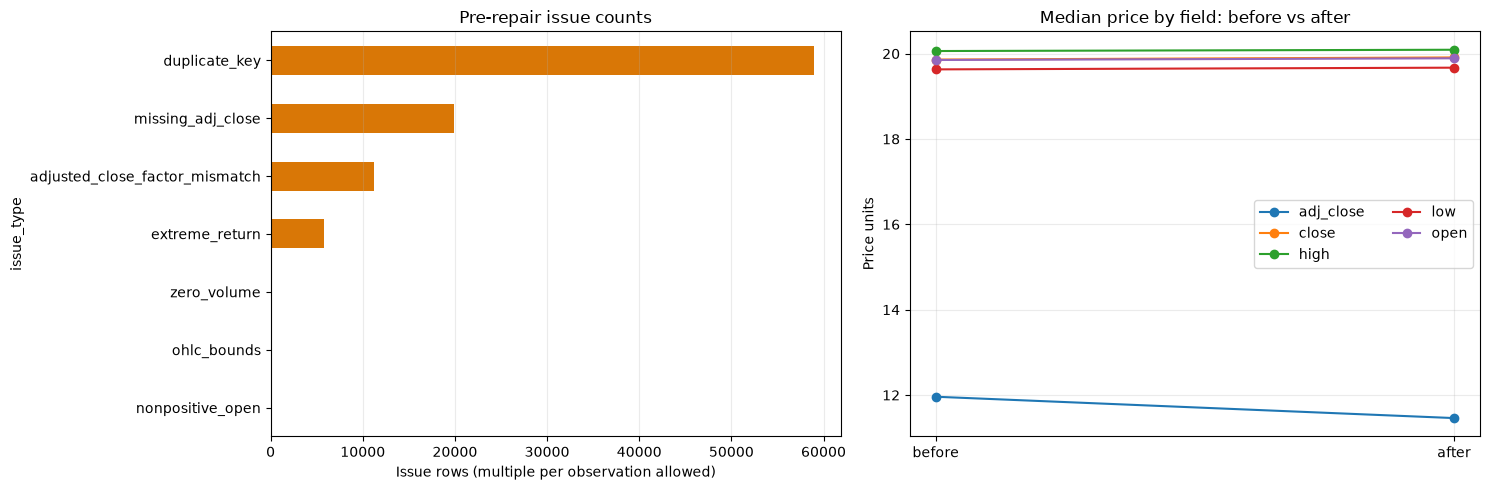

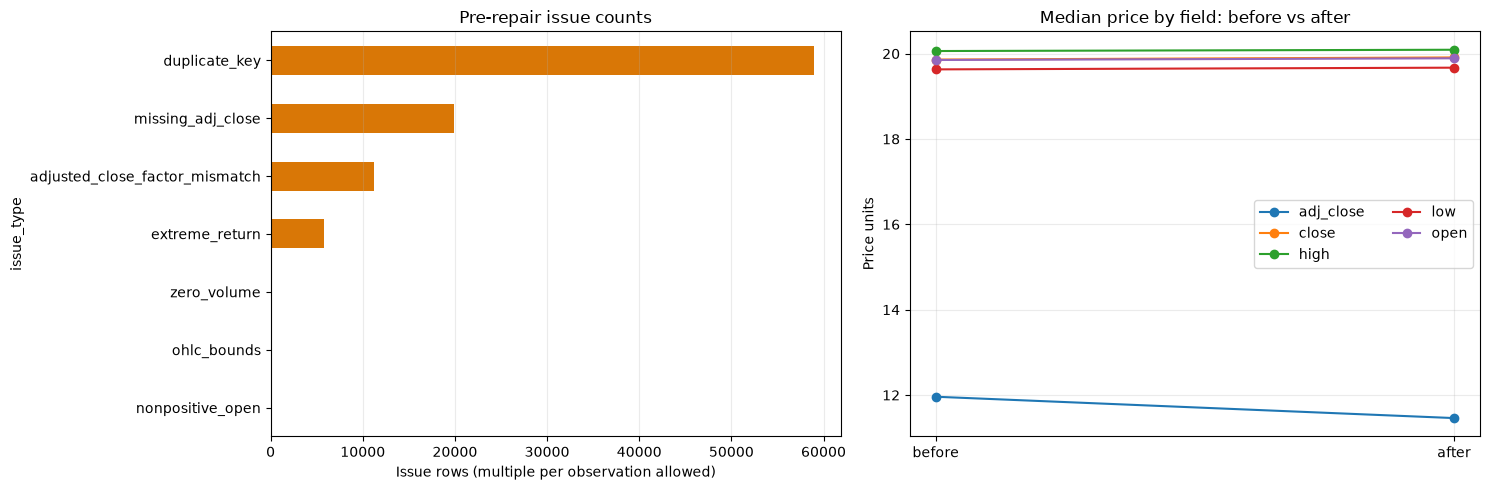

In [15]:
if not raw.empty:
    figure, axes = plt.subplots(1, 2, figsize=(15, 5))
    issue_counts = quality_report.groupby("issue_type").size().sort_values()
    issue_counts.plot.barh(ax=axes[0], color="#d97706")
    axes[0].set_title("Pre-repair issue counts")
    axes[0].set_xlabel("Issue rows (multiple per observation allowed)")
    axes[0].grid(axis="x", alpha=0.25)
    if not before_after.empty:
        for column, group in before_after.groupby("price_column"):
            axes[1].plot(group["stage"], group["median"], marker="o", label=column)
        axes[1].set_title("Median price by field: before vs after")
        axes[1].set_ylabel("Price units")
        axes[1].legend(ncol=2)
        axes[1].grid(alpha=0.25)
    figure.tight_layout()
    display(figure)
else:
    print("Real-data charts will appear after rerunning with the bCourses database.")

## Summary

### Q&A
- Missing rows were checked against the ticker-specific sessions in the supplied clean `ohlc` table, restricted to each ticker's observed `ohlc_hw` history. This dataset has **zero missing ticker-dates** under that reference calendar; weekdays were not substituted for an exchange calendar.
- Missing cells are distinct from missing rows. The raw table has 19,855 missing `adj_close` values; the other required fields have no missing values.
- Exact duplicate records were collapsed. Conflicting normalized `(ticker, ts)` records are quarantined rather than arbitrarily selected.

### Data Analysis Key Findings
- The source has 397,711 rows for 30 normalized tickers, spanning 1962-01-02 through 2024-12-06. Normalization revealed 150 raw ticker labels for 30 normalized tickers.
- Pre-repair diagnostics recorded 58,920 duplicate-key issue rows (29,460 exact duplicate rows removed), 5,741 extreme-return review flags, 5 impossible OHLC-bound observations, 5 nonpositive opens, 81 zero-volume observations, and 11,265 date-matched adjusted-close factor mismatches.
- Cleaning retained 368,246 rows, removed 29,460 exact duplicate rows, and quarantined 5 unresolved invalid rows. It repaired 28,791 cells, including 10,417 adjusted-close mismatches on retained rows. All 368,246 retained adjusted closes now agree with the same-date factor from `ohlc`; no adjustment factor was carried across dates.
- Retained rows pass validation for complete, finite, positive OHLC/adjusted prices, valid raw OHLC bounds, unique ticker/date keys, and finite nonnegative volume. Post-repair review still flags 5,057 extreme returns and 74 zero-volume rows; these remain review indicators rather than being silently erased.
- The root `data.db` was used only as a source. The cleaned table and separate pre-/post-repair quality and quarantine tables were saved in the personal HW2 working copy.

### Insights or Next Steps
- Review `ohlc_hw_quality_report`, `ohlc_hw_quarantine`, and `ohlc_hw_cleaned_quality_report` in `Homeworks/HW2/Mrityunjay_Balkrishnan/data/data.db` before interpreting downstream reports.
- The AAPL template example now runs on the corrected adjusted-close series: 202 observations through 2024-10-18, total return +27.07%, Sharpe 1.187, and maximum drawdown −15.35%. Other tickers have different coverage; the batch runner must report each actual range.